In [1]:
from fun import *

In [2]:
# Set all the encessary parameters for the code
Nx = 121 # No. of position steps
PsiSize = (Nx)
m = 1 #mass of an electon, used for natural units

Xa = -40 #size of system in nm
Xb = 40
dx = (Xb-Xa)/(Nx-1) #size of position step

hbar = 1 #hbar = 1 natural units

T = 1000 # 1 time unit here is 0.0086 ps
dt = 0.025 # time step needs to be small enough to obey energy stabilty dt ~ 1/( dx**2 + V_max)
Nt = int(T/dt)

x = np.linspace(Xa,Xb,Nx)


# Kinetic part of the Hamiltonian
HK = np.zeros([PsiSize, PsiSize], dtype=np.complex128)

hbar2 = hbar ** 2 #hbar squared

hk = hbar2 / (2 * m * dx ** 2)

# as kinetic energy is [ f(x+dx) - 2f(x) + f(x-dx)] / dx**2
for k in range(0, PsiSize):# Go over each row
    #fill Hamiltonian, making use of hermiticity to only fill half and do conjugate
 
    HK[k][k] += 2 * hk # on-site kinetic part

    pmone= k -1
    if (pmone>=0 and pmone<Nx):
        HK[k][k-1] -= hk

    pmone= k+1
    if (pmone>=0 and pmone< Nx ):
        HK[k][k+1] -= hk

Minima of the QWGB is :
22.878327395431604


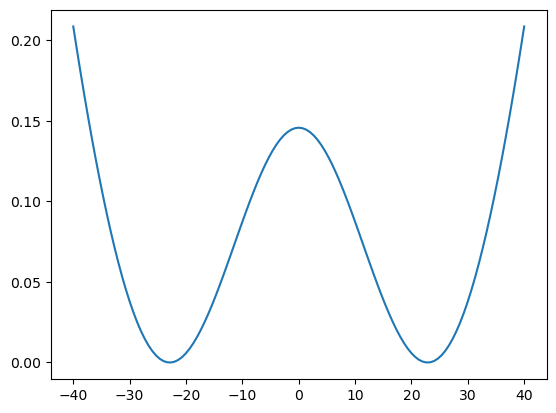

In [3]:
#set up and test potetnial params for quadratic well with gaussian barrier
w = 0.025 #quadratic well
hi = 0.45 # gaussian barrier inital height
hf = 0.0005 # gaussian barrier final height
wi = 15 # gaussian barrier intial width
wf = 0.5 # gaussian barrier final width
height = hi
sigma = wi
m = 1 / (3200) # linear bias strength
#V = get_Vg2m(Nt,w,Nx, Xa,wi,hi, hf,wf)

Vh = 0.5 * w**2 * x**2
Vg = Vh + gaussian(x,height,sigma)
Vl = m * x
#Vg += Vl
Vg = Vg - np.min(Vg) # Potetnial cant change to rapidly or descritisation errors can occur
plt.plot(x,Vg) # plot potetnial to make sure quadrtaic well and gaussian barrier make sense

print('Minima of the QWGB is :') # Minima of system, used to help choose x_offset
min = np.sqrt(-2*wi**2 * np.log((w**2 *wi**2)/hi))
print(min)

/home/sd875/micromamba/lib/python3.9/site-packages/matplotlib/cbook/__init__.py:1335: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


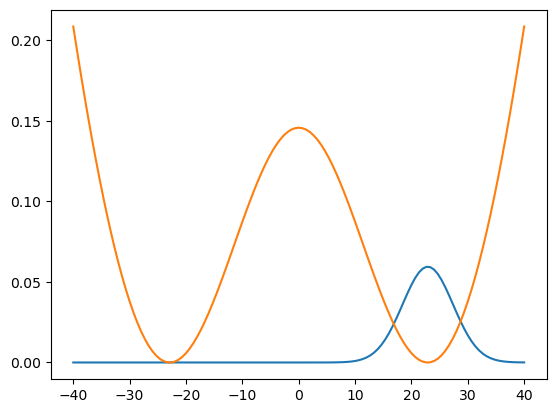

In [4]:
#Test wavefunction w.r.t potential

#minima of QWGB is [-2simga**2 * ln((w**2 * sigma**2)/h)]**0.5
xoffset = 22.9 # Wave packet distance from center
#w = 0.015
re = (w/np.pi)**(1/4)*np.exp(-w*(x-xoffset)**2/2) #chossen to be cohernt state for quadratic well with no gaussian barrier
#Changing the width to much can produce on charecteristic results.. so keep w on the order of quadratic well coherent state or 
#make sure to test result properly
psi = np.zeros(PsiSize, dtype=np.complex128)
psi += re
psi = psi / np.linalg.norm(psi)

#Plot wavefunction **2 and potetnial on same plot to see if intial state is sensible
plt.plot(x,psi**2)
plt.plot(x,Vg)

initial entropy: -4.441171261045854e-15


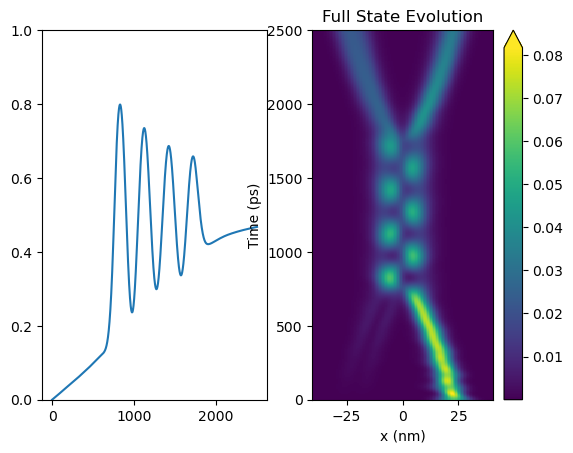

final entropy: 1.900087677002011
prob left channel is:  0.46760717372223126
452.6702604293823


In [31]:
#Ht, Rk4t, While getting hamiltonians as you go
initial = time.time()

T_channel = 1000 #"length" of center channel
T_conv = 750 #"length" of 2 channel convergance/divergance
T = T_channel + 2 * T_conv 
Nt = int(T/dt)
Nt_channel = int(T_channel/dt)
Nt_conv = int(T_conv/dt)

rho = np.outer(psi,psi)
psi2 = np.zeros([Nt,Nx])

print("initial entropy:" , get_entropy(rho).real)


#convergance 
Htdt = HK +np.diag(get_QWGBi(Nt,0,w,x,Xa,wi,hi,hf,wf))
ax_dt,adx_dt = get_ladderops(Htdt)
L1_dt,L2_dt,L3_dt = get_Lindblad(Htdt,ax_dt,adx_dt,w)
for i in range(0,Nt_conv):
    Ht = Htdt
    # Htstep = HK +np.diag(get_QWGBi(Nt_conv,i +1/2 ,w,x,Xa,wi,hi,hf,wf))
    # Htdt =   HK +np.diag(get_QWGBi(Nt_conv,i + 1 ,w,x,Xa,wi,hi,hf,wf))
    Htstep = HK +np.diag(get_QWGBLBi(Nt_conv,i +1/2 ,w,x,Xa,wi,hi,hf,wf,m))
    Htdt =   HK +np.diag(get_QWGBLBi(Nt_conv,i + 1 ,w,x,Xa,wi,hi,hf,wf,m))


    L1_t,L2_t,L3_t = L1_dt, L2_dt, L3_dt

    ax_step,adx_step = get_ladderops(Htstep)
    L1_step,L2_step,L3_step= get_Lindblad(Htdt,ax_step,adx_step,w)

    ax_dt,adx_dt = get_ladderops(Htdt)
    L1_dt,L2_dt,L3_dt = get_Lindblad(Htdt,ax_dt,adx_dt,w)

    drho = RK4t_step_L1L2L3(Ht,Htstep,Htdt,rho,dt,L1_t,L2_t,L3_t,
                     L1_step,L2_step,L3_step,L1_dt,L2_dt,L3_dt)
    rho += drho * dt
    psi2[i] = np.diag(rho).real


#center channel
for i in range(0, Nt_channel):
    drho = RK4_step_L1L2L3(Htdt,rho,dt,L1_dt,L2_dt,L3_dt) 
    rho += drho * dt
    psi2[i + Nt_conv] = np.diag(rho).real


#Divergance
for i in range(0,Nt_conv):
    Ht = Htdt
    # Htstep = HK +np.diag(get_QWGBi(Nt_conv,Nt_conv -i -1/2 ,w,x,Xa,wi,hi,hf,wf))
    # Htdt =   HK +np.diag(get_QWGBi(Nt_conv,Nt_conv - i - 1 ,w,x,Xa,wi,hi,hf,wf))
    Htstep = HK +np.diag(get_QWGBLBi(Nt_conv,Nt_conv -i -1/2 ,w,x,Xa,wi,hi,hf,wf,m))
    Htdt =   HK +np.diag(get_QWGBLBi(Nt_conv,Nt_conv - i - 1 ,w,x,Xa,wi,hi,hf,wf,m))



    L1_t,L2_t,L3_t = L1_dt, L2_dt, L3_dt

    ax_step,adx_step = get_ladderops(Htstep)
    L1_step,L2_step,L3_step= get_Lindblad(Htdt,ax_step,adx_step,w)

    ax_dt,adx_dt = get_ladderops(Htdt)
    L1_dt,L2_dt,L3_dt = get_Lindblad(Htdt,ax_dt,adx_dt,w)

    drho = RK4t_step_L1L2L3(Ht,Htstep,Htdt,rho,dt,L1_t,L2_t,L3_t,
                     L1_step,L2_step,L3_step,L1_dt,L2_dt,L3_dt)
    rho += drho * dt
    psi2[i + Nt_channel + Nt_conv] = np.diag(rho).real



#ploting

#make vector so first half is true
is_left = np.zeros(Nx)
for i in range(int(Nx//2)):
    is_left[i] = True
left_test = np.array(is_left, dtype=bool)

prob_left = np.sum(psi2, where = left_test, axis=1 )   

fig, (ax2, ax3) = plt.subplots(1, 2)
#fig.suptitle('Potential step at T=2000')


t = np.linspace(0,T,int(Nt))


ax2.plot(t,prob_left)
ax2.set_ylim([0,1])

pcm = ax3.pcolormesh(x, t, psi2)
ax3.set_title("Full State Evolution")
ax3.set_xlabel('x (nm)')
ax3.set_ylabel('Time (ps)')
fig.colorbar(pcm, ax=ax3, extend='max')
# fig.savefig("test.png")
plt.show()
print("final entropy:" , get_entropy(rho).real)
print("prob left channel is: " , prob_left[-1])
final = time.time()
print(final - initial)


/home/sd875/micromamba/lib/python3.9/site-packages/scipy/linalg/_matfuncs_inv_ssq.py:836: LogmNearlySingularWarning: The logm input matrix may be nearly singular.
  warnings.warn(near_singularity_msg, LogmNearlySingularWarning)


initial entropy: (-4.441171261045854e-15-4.2453479421095794e-16j)


/home/sd875/micromamba/lib/python3.9/site-packages/scipy/linalg/_matfuncs_inv_ssq.py:836: LogmNearlySingularWarning: The logm input matrix may be nearly singular.
  warnings.warn(near_singularity_msg, LogmNearlySingularWarning)


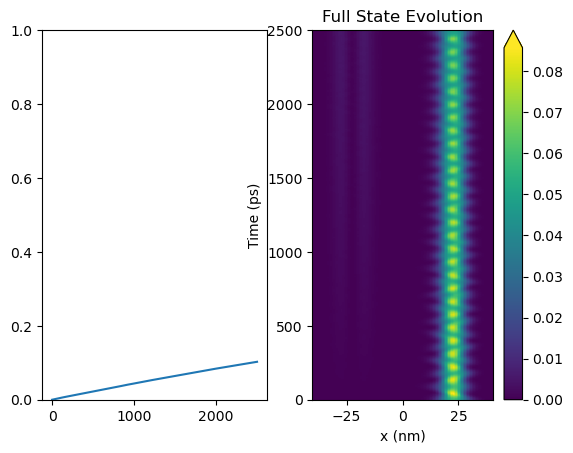

final entropy: (0.7097893230920114+2.9791934409134336e-08j)
166.08508706092834


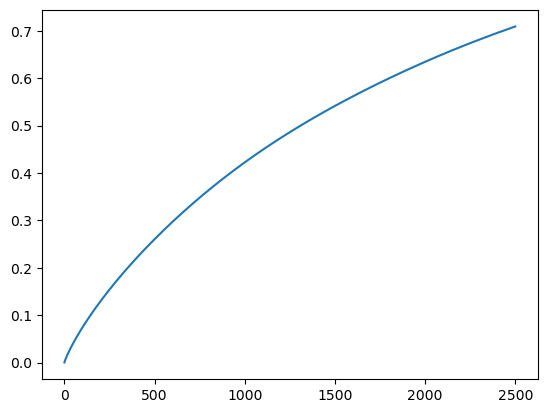

In [19]:
##Static Quadratic well gaussian barrier

initial = time.time()


Vh = 0.5 * w**2 * x**2
Vg = Vh + gaussian(x,height,sigma)
Vg = Vg - np.min(Vg)
H = HK + np.diag(Vg) #full hamiltontian


rho = np.outer(psi,psi)
#intial entropy
print("initial entropy:" , get_entropy(rho))


D, psi_eig = LA.eigh(H)
#Cant have psi2 be Nt long, so divivde by a and record every ath value
a = 2 #need Nt/a to be a integer vaguely want Nt/a to be order 10000
psi2 = np.zeros((int(Nt//a), int(PsiSize))) #records psi**2 for each recored time step


#get the Lindblad operators
ax,adx = get_ladderops(H)
L1,L2,L3 = get_Lindblad(H,ax,adx,w)


for i in range(0,int(Nt)):
    # rhodot = RK4_step(H,rho,dt)  
    # rhodot = RK4_step_L1(H,rho,L1,dt)
    # rhodot = RK4_step_L2(H,rho,L2,dt)
    rhodot = RK4_step_L3(H,rho,L3,dt)
    # rhodot = RK4_step_L1L2L3(Ht,rho,dt,L1,L2,L3)
    rho += rhodot*dt
    if i%a == True:
        psi2[i//a] = np.diag(rho).real #if i%a = 0.. records every ath value
    if i%S_updatef == True:
        S[i//S_updatef] = get_entropy(rho).real


#ploting

#make vector so first half is true
is_left = np.zeros(Nx)
for i in range(int(Nx//2)):
    is_left[i] = True
left_test = np.array(is_left, dtype=bool)
prob_left = np.sum(psi2, where = left_test, axis=1 )    

fig, (ax2, ax3) = plt.subplots(1, 2)
#fig.suptitle('Potential step at T=2000')


t = np.linspace(0,T,int(Nt//(a)))

# DMGraph = np.zeros((PsiSize,PsiSize), dtype=np.complex64)
# for i in range(PsiSize):
#     for j in range(PsiSize):
#         DMGraph[i][j] = np.conjugate(psi_eig[:,i])@rho@psi_eig[:,j]

# ax2.bar(np.arange(0, PsiSize), np.diag(DMGraph.real))
# ax2.set_title("Pure State ocupation")

ax2.plot(t,prob_left)
ax2.set_ylim([0,1])
pcm = ax3.pcolormesh(x, t, psi2)
ax3.set_title("Full State Evolution")
ax3.set_xlabel('x (nm)')
ax3.set_ylabel('Time (ps)')
fig.colorbar(pcm, ax=ax3, extend='max')
# fig.savefig("test.png")
plt.show()

#final entropy
print("final entropy:" , get_entropy(rho))


final = time.time()
print(final - initial)

In [ ]:
#wavefunction animation
fig, ax = plt.subplots()

ims = []
#only make picures every few time steps so code run time and animations are viewable
for i in range(Nt//(20*a)): # Nt// (x*a*40) for interval = 25 how many seconds ani is 
    #ax.set_ylim(0,0.01)
    im, = ax.plot(x, psi2[i*20], 'm', animated=True)
    ims.append([im])

ani = animation.ArtistAnimation(fig, ims, interval=25, blit=True,
                                repeat_delay=1000)


#writer = animation.FFMpegWriter(
#    fps=15, metadata=dict(artist='Me'), bitrate=1800)
#writergif = animation.PillowWriter(fps=30)
#ani.save('wavefunctionshift.gif',writer=writergif)
ani.save("test.mp4") #, writer=writer)

In [ ]:
#Get full time dependant potetnial as a Nt by Nx matrix
Potential = np.zeros([Nt,Nx])


for i in range(0,Nt_conv):
   Potential[i] = get_QWGBi(Nt_conv, i ,w,x,Xa,wi,hi,hf,wf)

for i in range(0,Nt_channel):
   Potential[Nt_conv + i] = Potential[Nt_conv -1]

for i in range(0,Nt_conv):
   Potential[Nt_conv+Nt_channel+i] = get_QWGBi(Nt_conv,Nt_conv -i,w,x,Xa,wi,hi,hf,wf)

In [ ]:
#Plot the wae function and potetnial on same animation
freq = 25
fig, ax = plt.subplots()

ims = []
for i in range(0,int(Nt/(a*freq))):
    im1, = ax.plot(x, Potential[i*freq*a],'k--',animated=True)
    im2, = ax.plot(x, psi2[i*freq],'r',animated= True)
    ims.append([im1 , im2])

ani = animation.ArtistAnimation(fig, ims, interval=25, blit=True)

ani.save("Animations/Potential+WF.mp4") 